# Sign-CatBoost: Figure 2 and Table 2

This notebook **fits nine sign-CatBoost models** for Table 2 and separately **refits every point in Figure 2** from the fixed nested training subsets. For Table 2, fitting uses the combined 90% train + validation data. For Figure 2, fitting uses 25%, 50% and 100% of the 70% train split and scoring uses the same 20% validation split for both methods. The fixed 10% local test is scored only after Table 2 fitting.

In [1]:
NAME="catboost"
from pathlib import Path
from datetime import datetime, timezone
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "splits/manifest.json").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from common import load_split
SEEDS = (42, 123, 2026)
RUN = ROOT / "results/notebook_reruns" / (NAME + "-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
RUN.mkdir(parents=True)
print("Split seed 67; training seeds", SEEDS)
print("Fresh run directory:", RUN.relative_to(ROOT))

Split seed 67; training seeds (42, 123, 2026)
Fresh run directory: results/notebook_reruns/catboost-20261119T021119938946Z


## Fit Table 2 models on 90% train + validation

In [2]:
from catboost.pipeline import train as cat_train, predict as cat_predict
models={}
for d in ("20","30","40"):
    for seed in SEEDS:
        target=RUN/f"K{d}_seed{seed}"
        manifest=cat_train(d,"training+validation",seed,target)
        models[d,seed]=target
        print(f'Fitted K{d} seed {seed}: {manifest["training_count"]} rows')

Fitted K20 seed 42: 10800 rows


Fitted K20 seed 123: 10800 rows


Fitted K20 seed 2026: 10800 rows


Fitted K30 seed 42: 18000 rows


Fitted K30 seed 123: 18000 rows


Fitted K30 seed 2026: 18000 rows


Fitted K40 seed 42: 28800 rows


Fitted K40 seed 123: 28800 rows


Fitted K40 seed 2026: 28800 rows


## Evaluate Table 2 on the fixed 10% local test

In [3]:
rows=[]
for d in ("20","30","40"):
    _,_,_,_,x_test,y_test=load_split(d)
    for seed in SEEDS:
        predictions,_=cat_predict(models[d,seed],x_test)
        rows.append({"dataset":d,"seed":seed,"correct":int(np.sum(predictions==y_test)),"test_size":len(y_test),"accuracy_pct":100*float(np.mean(predictions==y_test))})
runs=pd.DataFrame(rows)
runs.to_csv(RUN/"local_test_runs.csv",index=False)
summary=runs.groupby("dataset")["accuracy_pct"].agg(mean="mean",sd="std")
row={"Method":"Sign-CatBoost"}
for d in ("20","30","40"):
    row[f"K{d}"]=f'{summary.loc[d,"mean"]:.2f} ± {summary.loc[d,"sd"]:.2f}'
display(pd.DataFrame([row]).set_index("Method"))

,K20,K30,K40
Method,,,
Sign-CatBoost,93.44 ± 0.05,96.28 ± 0.25,96.24 ± 0.05


## Refit Figure 2 learning curves

`catboost.learning_curve.curve_runs` constructs and fits each quadratic logistic or CatBoost model on the stored nested training-subset indices. This cell writes all 36 fresh validation runs. The next cell plots them directly in the notebook at the final single-column size.

In [4]:
from catboost.learning_curve import curve_runs
curve=[]
for item in curve_runs(("20","30","40")):
    curve.append(item)
    print(f'K{item["dataset"]} {item["training_percent"]}% {item["method"]} seed {item["seed"]}: {item["accuracy_pct"]:.2f}%')
curve_path=RUN/"learning_curve_runs.csv"
pd.DataFrame(curve).to_csv(curve_path,index=False)
print("Saved freshly fitted learning-curve runs in",RUN.relative_to(ROOT))

K20 25% quadratic-logistic seed 42: 50.29%


K20 25% sign-catboost seed 42: 81.96%


K20 25% sign-catboost seed 123: 77.58%


K20 25% sign-catboost seed 2026: 83.25%
K20 50% quadratic-logistic seed 42: 51.92%


K20 50% sign-catboost seed 42: 89.46%


K20 50% sign-catboost seed 123: 88.38%


... (20 outputs left out)

K40 100% sign-catboost seed 42: 94.64%


K40 100% sign-catboost seed 123: 95.30%


K40 100% sign-catboost seed 2026: 95.00%


Saved freshly fitted learning-curve runs in results/notebook_reruns/catboost-20261119T021119938946Z


## Plot Figure 2 at its final paper size

This cell draws directly from the **fresh 36 model fits above**. The 3.25-inch canvas matches one paper column; the two legend rows sit between the CatBoost and quadratic curves, leaving more space for the data. Every label is 10 pt at native size.

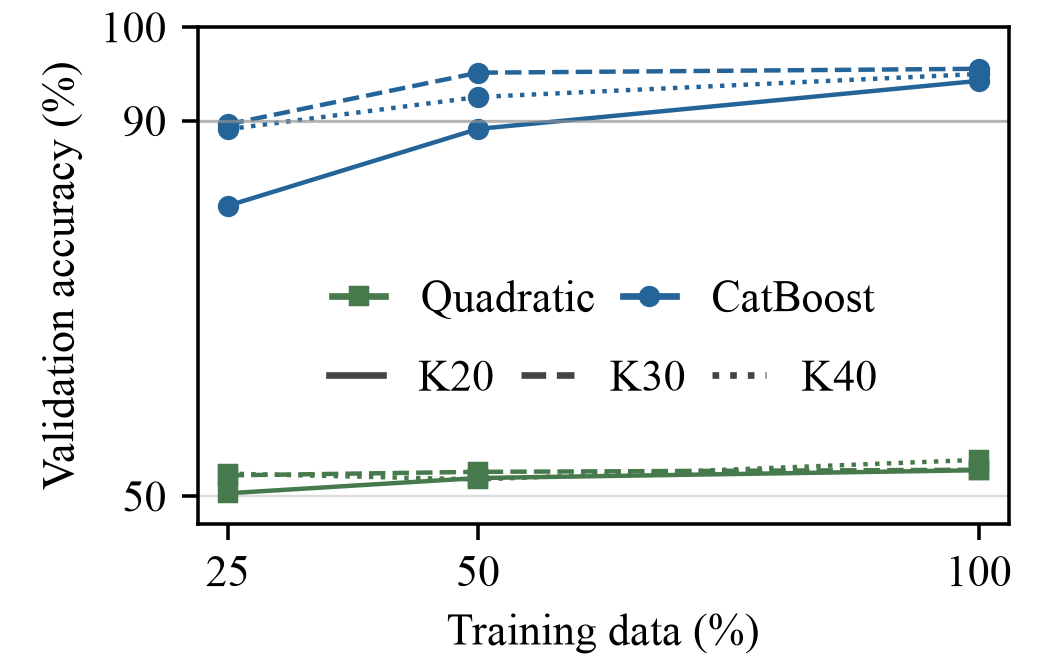

Figure 2 PDF: results/notebook_reruns/catboost-20261119T021119938946Z/figure2_single_column.pdf


In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Plot from this notebook's newly fitted runs, at the 3.25-inch paper-column width.
curve_data = pd.read_csv(curve_path)
assert len(curve_data) == 36
points = curve_data.groupby(["dataset", "method", "training_percent"])["accuracy_pct"].mean()
assert len(points) == 18
plt.rcParams.update({"font.family":"serif", "font.serif":["Times New Roman","Times"],
                     "font.size":10, "axes.labelsize":10, "xtick.labelsize":10,
                     "ytick.labelsize":10, "pdf.fonttype":42})
fig = plt.figure(figsize=(3.25,2.10), facecolor="white")
ax = fig.add_axes([0.19,0.22,0.78,0.74])
colors={"quadratic-logistic":"#46794c", "sign-catboost":"#256498"}
markers={"quadratic-logistic":"s", "sign-catboost":"o"}
styles={"20":"-", "30":"--", "40":":"}
for method in ("quadratic-logistic","sign-catboost"):
    for dataset in ("20","30","40"):
        values=[points.loc[(int(dataset),method,p)] for p in (25,50,100)]
        ax.plot((25,50,100), values, color=colors[method], marker=markers[method],
                linestyle=styles[dataset], markersize=3.8, linewidth=1.0)
ax.axhline(90,color="#999999",linewidth=0.7,alpha=0.6)
ax.set(xlim=(22,103),ylim=(47,100),xticks=(25,50,100),yticks=(50,90,100),
       xlabel="Training data (%)",ylabel="Validation accuracy (%)")
ax.grid(axis="y",color="#dddddd",linewidth=0.55)
method_handles=[Line2D([],[],color=colors[m],marker=markers[m],linestyle="-",
                       markersize=3.8,label=label) for m,label in
                (("quadratic-logistic","Quadratic"),("sign-catboost","CatBoost"))]
dataset_handles=[Line2D([],[],color="#444444",linestyle=styles[d],label=f"K{d}")
                 for d in ("20","30","40")]
# The space between the two method families holds both legends, so the
# plotted data occupy most of this single-column canvas.
method_legend=ax.legend(handles=method_handles,loc="center",bbox_to_anchor=(0.50,0.45),
                        ncol=2,frameon=True,facecolor="white",edgecolor="none",
                        framealpha=1,columnspacing=0.6,handlelength=1.2,fontsize=10)
ax.add_artist(method_legend)
ax.legend(handles=dataset_handles,loc="center",bbox_to_anchor=(0.50,0.29),
          ncol=3,frameon=True,facecolor="white",edgecolor="none",
          framealpha=1,columnspacing=0.6,handlelength=1.2,fontsize=10)
figure_png=RUN/"figure2_single_column.png"
figure_pdf=RUN/"figure2_single_column.pdf"
fig.savefig(figure_png,dpi=320,facecolor="white")
fig.savefig(figure_pdf,facecolor="white")
plt.close(fig)
display(Image(filename=str(figure_png)))
print("Figure 2 PDF:",figure_pdf.relative_to(ROOT))